<a href="https://colab.research.google.com/github/joao-araujoo/modelagem-computacional/blob/main/segmentacao_pluma_SAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentação de uma pluma de fumaça com o SAM

Atividade de Modelagem Computacional.

A ideia aqui é usar o SAM (Segment Anything, versão 2.1, pela biblioteca Ultralytics que a gente usou nas aulas) para separar a pluma de fumaça do resto da imagem.

O que eu fiz, na ordem:
1. Instalei e carreguei o modelo e escolhi a imagem.
2. Escrevi umas funções para rodar o SAM, desenhar os resultados e calcular algumas métricas.
3. Fiz o código achar a pluma sozinho e gerar a caixa e os pontos (para não depender de coordenadas digitadas na mão).
4. Rodei a linha de base (sem prompt e com 1 ponto só) para ver o que dá errado.
5. Testei 5 configurações de prompt e mostrei original, máscara binária e sobreposição lado a lado.
6. Fiz um pós-processamento para limpar a máscara.
7. Analisei iluminação, contraste e a semelhança entre fumaça e nuvem.
8. Testei o que acontece quando mudo o brilho e o contraste da imagem.


## 1. Instalação e importações
Usei o `sam2.1_b.pt` (versão base). Testei o `sam2.1_t` também; é mais rápido, mas as bordas ficam piores.

In [ ]:
!pip install -q ultralytics

import os, urllib.request
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import display
from ultralytics import SAM

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Dispositivo:", "GPU" if DEVICE == 0 else "CPU")

# SAM 2.1 base. Alternativas: "sam2.1_t.pt" (mais rápido), "sam2.1_l.pt" (mais preciso), "sam_b.pt" (SAM original)
model = SAM("sam2.1_b.pt")
model.info()

Dispositivo: GPU
Model summary: 436 layers, 80,850,178 parameters, 80,850,178 gradients


(436, 80850178, 80850178, 0.0)

## 2. Escolha da imagem
Ao rodar, abre a janelinha para escolher o arquivo. Deixei o código redimensionar imagens muito grandes (lado maior até 1280 px), porque senão o SAM fica lento e as coordenadas ficam difíceis de ler.

In [ ]:
IMAGEM = ""            # vazio = abre a janela para escolher o arquivo (ou coloque o nome do arquivo)
URL_IMAGEM = ""        # <-- opcional: link direto para a imagem

if not IMAGEM or not os.path.exists(IMAGEM):
    if URL_IMAGEM:
        urllib.request.urlretrieve(URL_IMAGEM, IMAGEM)
    else:
        from google.colab import files
        enviado = files.upload()
        IMAGEM = list(enviado.keys())[0]

img_bgr = cv2.imread(IMAGEM)
assert img_bgr is not None, f"Não consegui ler {IMAGEM}"
# Imagens muito grandes deixam o SAM lento e as coordenadas difíceis de ler: limita o lado maior a 1280 px
MAX_LADO = 1280
esc = MAX_LADO / max(img_bgr.shape[:2])
if esc < 1:
    img_bgr = cv2.resize(img_bgr, None, fx=esc, fy=esc, interpolation=cv2.INTER_AREA)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
H, W = img_rgb.shape[:2]
print(f"Imagem: {W} x {H} px")

Saving istockphoto-167231386-612x612.jpg to istockphoto-167231386-612x612.jpg
Imagem: 612 x 408 px


## 3. Grade de coordenadas
Pus uma grade em cima da imagem para conseguir ler as coordenadas em pixels. No começo eu estava chutando os pontos e errava muito, então isso ajudou. Também serve para conferir se os prompts automáticos fazem sentido, ou para usar o modo manual.

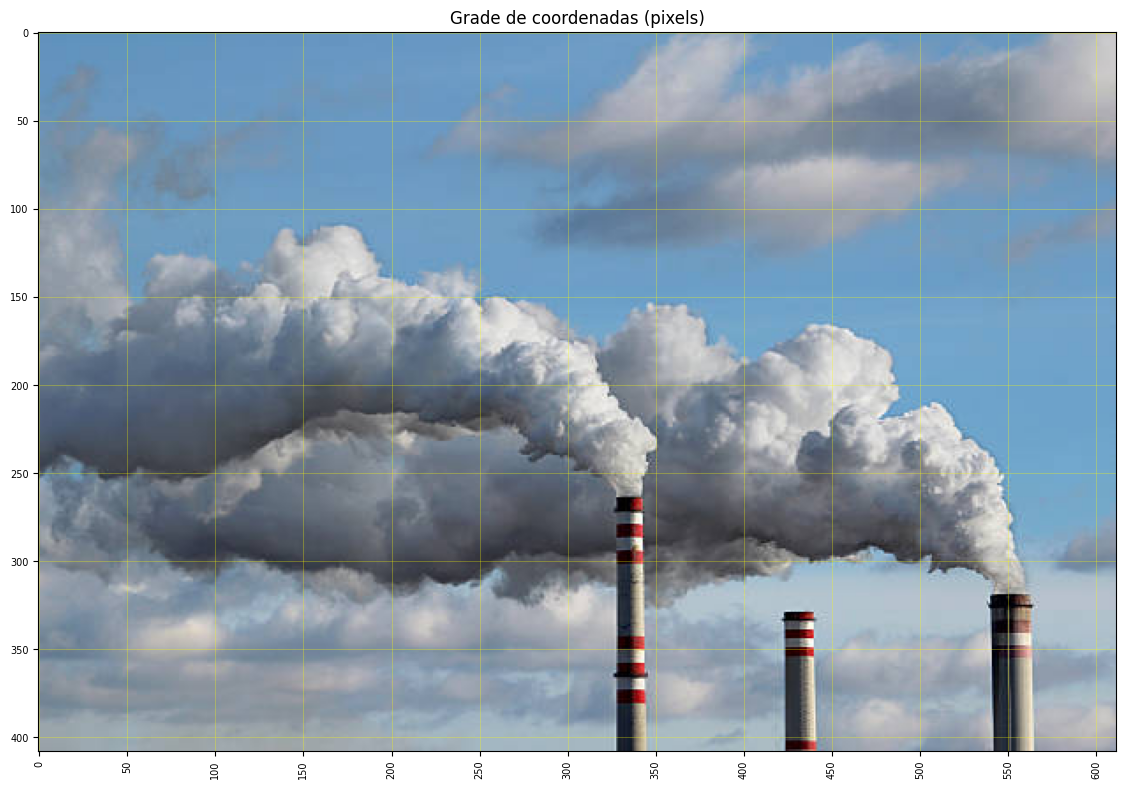

In [ ]:
def mostrar_grade(img, passo=50):
    fig, ax = plt.subplots(figsize=(14, 14 * img.shape[0] / img.shape[1]))
    ax.imshow(img)
    ax.set_xticks(np.arange(0, img.shape[1], passo))
    ax.set_yticks(np.arange(0, img.shape[0], passo))
    ax.tick_params(labelsize=7)
    plt.setp(ax.get_xticklabels(), rotation=90)
    ax.grid(color="yellow", alpha=0.35, linewidth=0.6)
    ax.set_title("Grade de coordenadas (pixels)")
    plt.show()

mostrar_grade(img_rgb, passo=50)

## 4. Funções auxiliares
Separei em funções o que eu ia repetir várias vezes:
- `segmentar`: roda o SAM com caixa, pontos positivos e pontos negativos. Um detalhe que me pegou: para vários pontos valerem para o mesmo objeto, a lista tem que ir aninhada (`points=[[p1, p2, ...]]`). Se não for aninhada, o SAM acha que cada ponto é um objeto diferente.
- `sobrepor` e `painel`: desenham a máscara por cima da imagem, com contorno amarelo, e montam a figura com original | binária | sobreposta.
- `metricas`: como eu não tenho uma máscara "gabarito", criei medidas indiretas. Vejo quanto a máscara cobre de pequenas amostras de pluma, nuvem, céu e prédio. Também comparo a cor dentro e fora da borda (ΔE) e vejo se o contorno está em cima de uma borda de verdade da imagem.

In [ ]:
CORES = {"pos": "#00e676", "neg": "#ff1744", "box": "#ffd600"}

def segmentar(img, bbox=None, bboxes=None, pos=(), neg=()):
    # Executa o SAM com os prompts e devolve uma máscara booleana (H, W).
    # bbox + pos + neg -> um único objeto; bboxes -> um objeto por caixa (máscaras unidas).
    pts = [list(p) for p in pos] + [list(p) for p in neg]
    lab = [1] * len(pos) + [0] * len(neg)
    kw = {}
    if bboxes:
        kw["bboxes"] = bboxes
    elif bbox is not None:
        kw["bboxes"] = [bbox]
    if pts and not bboxes:
        kw["points"], kw["labels"] = [pts], [lab]   # lista aninhada = vários pontos para o MESMO objeto
    r = model(cv2.cvtColor(img, cv2.COLOR_RGB2BGR), device=DEVICE, verbose=False, **kw)[0]
    if r.masks is None:
        return np.zeros(img.shape[:2], bool)
    return r.masks.data.cpu().numpy().astype(bool).any(0)

def sobrepor(img, mask, cor=(255, 40, 40), alfa=0.45, contorno=True):
    out = img.copy().astype(np.float32)
    out[mask] = (1 - alfa) * out[mask] + alfa * np.array(cor, np.float32)
    out = out.astype(np.uint8)
    if contorno:
        cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(out, cnts, -1, (255, 255, 0), 2)
    return out

def desenhar_prompts(ax, cfg):
    for b in ([cfg["bbox"]] if cfg.get("bbox") is not None else []) + cfg.get("bboxes", []):
        ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=CORES["box"], lw=2))
    if cfg.get("pos"):
        p = np.array(cfg["pos"]); ax.scatter(p[:, 0], p[:, 1], c=CORES["pos"], marker="*", s=260, edgecolors="k", linewidths=1)
    if cfg.get("neg"):
        n = np.array(cfg["neg"]); ax.scatter(n[:, 0], n[:, 1], c=CORES["neg"], marker="X", s=160, edgecolors="k", linewidths=1)

def painel(resultados, img, titulo=None):
    # Uma linha por configuração: original+prompts | máscara binária | sobreposição
    n = len(resultados)
    fig, axs = plt.subplots(n, 3, figsize=(16, 4.4 * n * H / W * 1.45 + 0.5))
    axs = np.atleast_2d(axs)
    for i, (nome, (cfg, m)) in enumerate(resultados.items()):
        axs[i, 0].imshow(img); desenhar_prompts(axs[i, 0], cfg)
        axs[i, 0].set_title(f"{nome}\noriginal + prompts", fontsize=10)
        axs[i, 1].imshow(m, cmap="gray"); axs[i, 1].set_title(f"máscara binária ({100 * m.mean():.1f}% da imagem)", fontsize=10)
        axs[i, 2].imshow(sobrepor(img, m)); axs[i, 2].set_title("máscara sobreposta", fontsize=10)
        for a in axs[i]: a.axis("off")
    if titulo: fig.suptitle(titulo, fontsize=13, y=1.0)
    plt.tight_layout(); plt.show()

def cobertura(mask, b):
    x1, y1, x2, y2 = [int(v) for v in b]
    r = mask[max(0, y1):y2, max(0, x1):x2]
    return float(r.mean()) if r.size else 0.0

def metricas(mask, img, amostras):
    # Métricas sem verdade de campo completa.
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float32)
    m8 = mask.astype(np.uint8)
    n_comp = cv2.connectedComponents(m8)[0] - 1
    # anel externo de 15 px: compara a cor de dentro com a cor logo fora da borda
    anel = cv2.dilate(m8, np.ones((31, 31), np.uint8)).astype(bool) & ~mask
    dE = np.linalg.norm(lab[mask].mean(0) - lab[anel].mean(0)) if mask.any() and anel.any() else np.nan
    # força das bordas da imagem sobre o contorno da máscara
    cinza = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    grad = np.hypot(cv2.Sobel(cinza, cv2.CV_32F, 1, 0), cv2.Sobel(cinza, cv2.CV_32F, 0, 1))
    contorno = cv2.morphologyEx(m8, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)).astype(bool)
    toca_borda = mask[0].any() or mask[-1].any() or mask[:, 0].any() or mask[:, -1].any()
    d = {"área %": 100 * mask.mean(), "componentes": n_comp,
         "ΔE dentro×fora": dE, "gradiente no contorno": grad[contorno].mean() if contorno.any() else np.nan,
         "toca borda da imagem": "sim" if toca_borda else "não"}
    for k, b in amostras.items():
        d[f"cobre {k} %"] = 100 * cobertura(mask, b)
    return d

def tabela(res_metricas):
    import pandas as pd
    df = pd.DataFrame(res_metricas).T
    return df.style.format(precision=1)

## 5. Prompts automáticos
Primeiro eu fiz com coordenadas digitadas na mão, mas aí cada imagem precisava de valores novos. Pior: quando errei a posição, o ponto caiu em cima da chaminé e o SAM segmentou a chaminé em vez da fumaça. Então fiz o código achar a pluma sozinho:

1. Cor: fumaça é branca ou cinza, ou seja, tem pouca saturação. Só que isso também pega as nuvens.
2. Textura: a fumaça perto das chaminés é densa e cheia de relevo claro/escuro. As nuvens do fundo são mais lisas. Então calculei o desvio padrão do brilho numa janelinha e fiquei só com as partes pouco saturadas e com bastante textura.
3. Fiquei com a maior mancha, preferindo as que chegam mais perto do chão (a pluma sai da chaminé).
4. Dividi a mancha em 3 trechos ao longo do lado mais comprido e coloquei um ponto positivo no "meio" de cada trecho (máximo da transformada de distância).
5. Refinamento em 2 passos: rodo o SAM só com esses pontos e uso a máscara que ele devolve para ajustar a caixa. Fiz isso porque a mancha de textura descia até as nuvens de baixo e a caixa ficava grande demais.
6. Pontos negativos: no céu azul, nas nuvens lisas e em regiões de cor forte (as listras vermelhas das chaminés).

Se precisar, dá para trocar `MODO_PROMPTS = "manual"` e colocar os valores na mão.

PONTO_BASE = (445, 214)
BBOX = [0, 98, 570, 352]
POS = [(163, 142), (296, 210), (445, 214)]
NEG = [(163, 49), (564, 174), (580, 37), (126, 383), (543, 350)]
NEG_BORDA = [(126, 383), (163, 49), (543, 350)]
BBOXES_TRECHO = [[0, 98, 197, 352], [174, 109, 383, 333], [360, 149, 570, 326]]
AMOSTRAS = {'pluma': [429, 198, 461, 230], 'pluma início': [147, 126, 179, 158], 'pluma fim': [429, 198, 461, 230], 'nuvem': [564, 21, 596, 53], 'céu': [147, 33, 179, 65], 'edifício': [539, 346, 547, 354]}


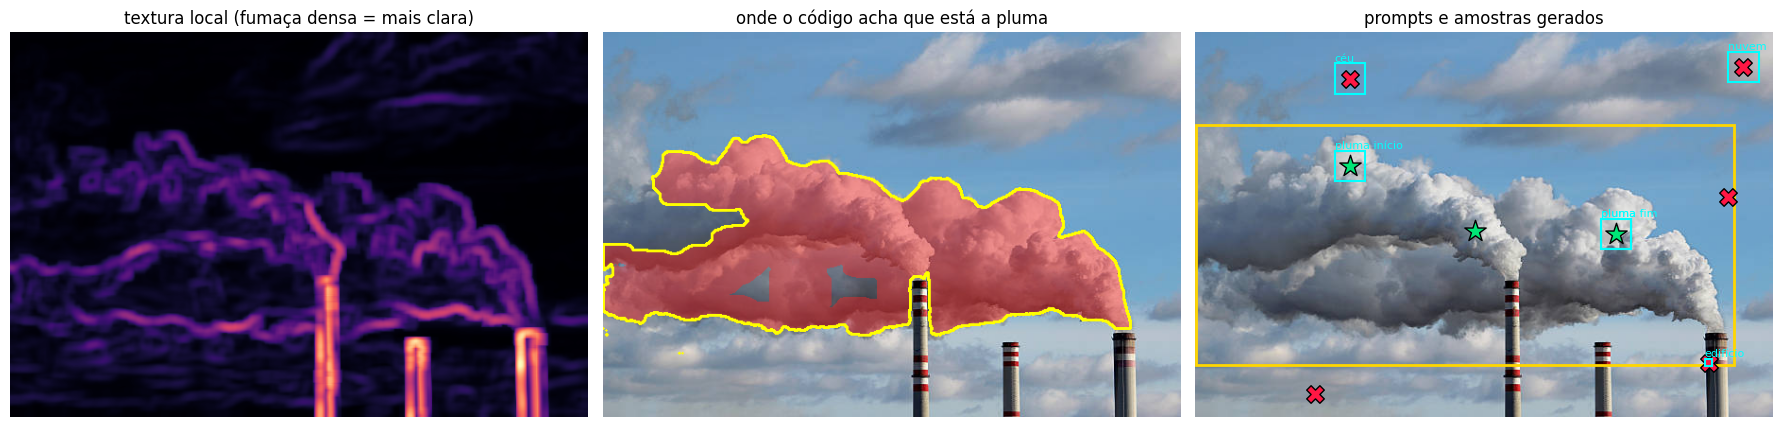

In [ ]:
MODO_PROMPTS = "auto"     # "auto" = o código acha a pluma sozinho | "manual" = usa os valores lá embaixo

hsv_ = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV).astype(np.float32)
HUE, SAT, VAL = hsv_[..., 0], hsv_[..., 1] / 255, hsv_[..., 2] / 255
cinza_ = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)

# textura local = desvio padrão do brilho numa janelinha (fumaça densa tem muito relevo claro/escuro)
K = max(9, int(0.03 * min(H, W)) | 1)
TEXTURA = np.sqrt(np.maximum(cv2.blur(cinza_ ** 2, (K, K)) - cv2.blur(cinza_, (K, K)) ** 2, 0))

# 1) pixels "cor de fumaça": pouco saturados e não muito escuros (isso pega fumaça E nuvem)
cor_fumaca = (SAT < 0.25) & (VAL > 0.30)
# 2) a fumaça perto da chaminé é densa e tem muita textura; nuvem de fundo é mais lisa
lim_tex = np.percentile(TEXTURA[cor_fumaca], 50) if cor_fumaca.any() else TEXTURA.mean()
mapa_fumaca = (cor_fumaca & (TEXTURA > lim_tex)).astype(np.uint8)
ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (K, K))
mapa_fumaca = cv2.morphologyEx(mapa_fumaca, cv2.MORPH_CLOSE, ker)
mapa_fumaca = cv2.morphologyEx(mapa_fumaca, cv2.MORPH_OPEN, ker)
# 3) fica com a maior mancha, dando preferência às que descem mais (a pluma sai de baixo, da chaminé/fogo)
n_, rot_, st_, _ = cv2.connectedComponentsWithStats(mapa_fumaca, 8)
if n_ > 1:
    notas = [st_[i, cv2.CC_STAT_AREA] * ((st_[i, 1] + st_[i, 3]) / H) ** 2 for i in range(1, n_)]
    m_cand = rot_ == 1 + int(np.argmax(notas))
else:
    m_cand = cor_fumaca

def ponto_central(m):
    # ponto mais "para dentro" da região (máximo da transformada de distância)
    m = m.copy(); m[[0, -1], :] = False; m[:, [0, -1]] = False   # borda da imagem conta como "fora"
    if not m.any():
        return None, 0.0
    dist = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 5)
    y, x = np.unravel_index(dist.argmax(), dist.shape)
    return (int(x), int(y)), float(dist.max())

def caixa_amostra(p, r):
    lado = max(4, int(min(r * 0.7, 0.04 * min(H, W))))
    return [max(0, p[0] - lado), max(0, p[1] - lado), min(W, p[0] + lado), min(H, p[1] + lado)]

ys, xs = np.where(m_cand)
x1, y1, x2, y2 = xs.min(), ys.min(), xs.max(), ys.max()
mg = int(0.02 * max(W, H))
BBOX = [int(max(0, x1 - mg)), int(max(0, y1 - mg)), int(min(W - 1, x2 + mg)), int(min(H - 1, y2 + mg))]

# divide a pluma em 3 trechos ao longo do lado mais comprido (pluma em pé ou deitada)
horizontal = (x2 - x1) > (y2 - y1)
a0, a1 = (x1, x2 + 1) if horizontal else (y1, y2 + 1)
cortes = np.linspace(a0, a1, 4).astype(int)
POS, raios, BBOXES_TRECHO = [], [], []
for c0, c1 in zip(cortes[:-1], cortes[1:]):
    faixa = np.zeros_like(m_cand)
    if horizontal: faixa[:, c0:c1] = m_cand[:, c0:c1]
    else:          faixa[c0:c1, :] = m_cand[c0:c1, :]
    p, r = ponto_central(faixa)
    if p:
        POS.append(p); raios.append(r)
        fy, fx = np.where(faixa)
        BBOXES_TRECHO.append([int(max(0, fx.min() - mg)), int(max(0, fy.min() - mg)),
                              int(min(W - 1, fx.max() + mg)), int(min(H - 1, fy.max() + mg))])
PONTO_BASE, r_meio = ponto_central(m_cand)

# refinamento em 2 passos: roda o SAM só com os pontos positivos e usa a máscara dele para
# ajustar a caixa (a mancha de textura costuma descer até as nuvens de baixo e as chaminés)
m_pos = segmentar(img_rgb, pos=POS)
if 0.01 < m_pos.mean() < 0.8:
    m_ref = m_pos & cv2.dilate(m_cand.astype(np.uint8), np.ones((2 * mg + 1, 2 * mg + 1), np.uint8)).astype(bool)
    m_ref = m_ref if m_ref.sum() > 0.5 * m_pos.sum() else m_pos
    ys, xs = np.where(m_ref)
    x1, y1, x2, y2 = xs.min(), ys.min(), xs.max(), ys.max()
    BBOX = [int(max(0, x1 - mg)), int(max(0, y1 - mg)), int(min(W - 1, x2 + mg)), int(min(H - 1, y2 + mg))]
    BBOXES_TRECHO = []
    cortes = np.linspace(x1, x2 + 1, 4).astype(int) if horizontal else np.linspace(y1, y2 + 1, 4).astype(int)
    for c0, c1 in zip(cortes[:-1], cortes[1:]):
        faixa = np.zeros_like(m_ref)
        if horizontal: faixa[:, c0:c1] = m_ref[:, c0:c1]
        else:          faixa[c0:c1, :] = m_ref[c0:c1, :]
        if faixa.sum() > 50:
            fy, fx = np.where(faixa)
            BBOXES_TRECHO.append([int(max(0, fx.min() - mg)), int(max(0, fy.min() - mg)),
                                  int(min(W - 1, fx.max() + mg)), int(min(H - 1, fy.max() + mg))])
    m_cand = m_ref

# pontos negativos: céu, nuvens lisas e estruturas (chaminé, prédio, chão)
longe = ~cv2.dilate(m_cand.astype(np.uint8), np.ones((2 * mg + 1, 2 * mg + 1), np.uint8)).astype(bool)
ceu = (SAT > 0.30) & (HUE > 85) & (HUE < 135) & longe
nuvem_lisa = cor_fumaca & (TEXTURA < lim_tex) & longe
estrutura = ((SAT > 0.40) & (VAL > 0.25) & ~((HUE > 85) & (HUE < 135))) | (VAL < 0.15)   # cor forte que não é céu (chaminé listrada) ou muito escuro

NEG, AMOSTRAS_EXTRA = [], {}
for nome, reg, qtd in [("céu", ceu, 2), ("nuvem", nuvem_lisa, 2)]:
    reg = reg.copy()
    for _ in range(qtd):
        p, r = ponto_central(reg)
        if p is None or r < 3: break
        NEG.append(p)
        AMOSTRAS_EXTRA.setdefault(nome, caixa_amostra(p, r))
        reg[max(0, p[1] - int(3 * r)):p[1] + int(3 * r), max(0, p[0] - int(3 * r)):p[0] + int(3 * r)] = False
n_e, rot_e, st_e, cen_e = cv2.connectedComponentsWithStats(cv2.morphologyEx(estrutura.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)), 8)
for i in np.argsort(-st_e[1:, cv2.CC_STAT_AREA])[:3] + 1:
    if st_e[i, cv2.CC_STAT_AREA] > 0.0005 * H * W:
        p, r = ponto_central(rot_e == i)
        NEG.append(p); AMOSTRAS_EXTRA.setdefault("edifício", caixa_amostra(p, max(r, 4)))

def caixa_reserva(score):
    s = cv2.blur(np.where(m_cand, -1e3, score).astype(np.float32), (31, 31))
    y, x = np.unravel_index(s.argmax(), s.shape)
    return caixa_amostra((int(x), int(y)), 20)

AMOSTRAS = {"pluma": caixa_amostra(PONTO_BASE, r_meio)}
if len(POS) == 3:
    AMOSTRAS["pluma início"] = caixa_amostra(POS[0], raios[0])
    AMOSTRAS["pluma fim"] = caixa_amostra(POS[2], raios[2])
AMOSTRAS["nuvem"] = AMOSTRAS_EXTRA.get("nuvem") or caixa_reserva(VAL * (1 - SAT))
AMOSTRAS["céu"] = AMOSTRAS_EXTRA.get("céu") or caixa_reserva(SAT)
AMOSTRAS["edifício"] = AMOSTRAS_EXTRA.get("edifício") or caixa_reserva(1 - VAL)   # chaminé/prédio/chão

# negativos "de borda" para a C4: os 3 negativos mais perto da pluma
cy, cx = ys.mean(), xs.mean()
NEG_BORDA = sorted(NEG, key=lambda p: (p[0] - cx) ** 2 + (p[1] - cy) ** 2)[:3]

# ---------- valores manuais (só valem com MODO_PROMPTS = "manual"); use a grade da seção 3 ----------
if MODO_PROMPTS == "manual":
    PONTO_BASE = (300, 180)
    BBOX = [0, 80, 480, 280]
    POS = [(130, 150), (300, 180), (420, 200)]
    NEG = [(150, 40), (470, 130), (280, 300), (360, 300)]
    NEG_BORDA = [(280, 300), (360, 300), (470, 130)]
    BBOXES_TRECHO = [[0, 80, 170, 280], [150, 80, 330, 280], [310, 120, 480, 280]]
    AMOSTRAS = {"pluma": [280, 160, 320, 200], "nuvem": [300, 60, 360, 90],
                "céu": [130, 20, 180, 60], "edifício": [455, 280, 470, 330]}

CONFIGS = {
    "C1 · Caixa":                     dict(bbox=BBOX),
    "C2 · Pontos positivos":          dict(pos=POS),
    "C3 · Pontos + e −":              dict(pos=POS, neg=NEG),
    "C4 · Caixa + pontos + e −":      dict(bbox=BBOX, pos=POS, neg=NEG_BORDA),
    "C5 · Caixas por trecho (união)": dict(bboxes=BBOXES_TRECHO),
}

for nome in ["PONTO_BASE", "BBOX", "POS", "NEG", "NEG_BORDA", "BBOXES_TRECHO", "AMOSTRAS"]:
    print(nome, "=", globals()[nome])

fig, axs = plt.subplots(1, 3, figsize=(18, 5.2 * H / W * 1.45))
axs[0].imshow(TEXTURA, cmap="magma"); axs[0].set_title("textura local (fumaça densa = mais clara)")
axs[1].imshow(sobrepor(img_rgb, m_cand)); axs[1].set_title("onde o código acha que está a pluma")
axs[2].imshow(img_rgb); desenhar_prompts(axs[2], dict(bbox=BBOX, pos=POS, neg=NEG))
for nome, b in AMOSTRAS.items():
    axs[2].add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="cyan", lw=1.5))
    axs[2].text(b[0], max(8, b[1] - 3), nome, color="cyan", fontsize=8)
axs[2].set_title("prompts e amostras gerados")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

## 6. Linha de base: o que acontece sem cuidar dos prompts?

### 6.1 Segmentação automática (sem prompt)
Sem prompt, o SAM tenta dividir a imagem inteira em objetos. Na minha imagem ele nem achou a fumaça: gerou só umas 4 regiões, que eram as chaminés e um pedaço de nuvem. Faz sentido. As chaminés têm borda bem definida e "parecem objeto", enquanto a fumaça é difusa, não tem contorno claro e o modelo dá uma confiança baixa para ela.

O modo automático gerou 4 máscaras.


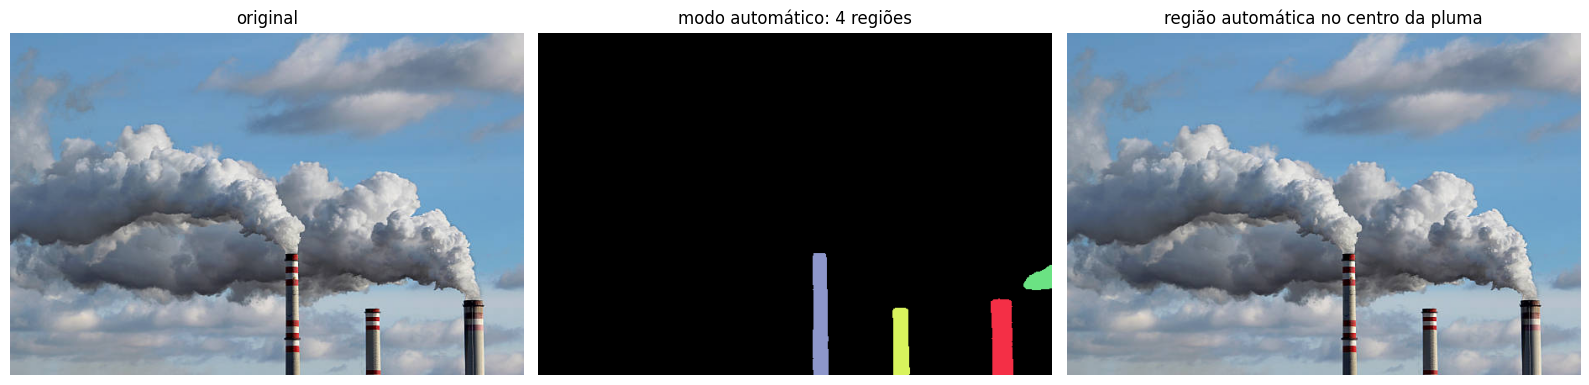

In [ ]:
RODAR_AUTOMATICO = True   # na GPU é rapidinho; na CPU demora uns minutos

r_auto = model(img_bgr, device=DEVICE, verbose=False)[0]
masks_auto = r_auto.masks.data.cpu().numpy().astype(bool) if r_auto.masks is not None else np.zeros((0, H, W), bool)
print(f"O modo automático gerou {len(masks_auto)} máscaras.")
cob = np.array([cobertura(m, AMOSTRAS["pluma"]) for m in masks_auto])
m_auto = masks_auto[cob.argmax()] if len(masks_auto) and cob.max() > 0 else np.zeros((H, W), bool)

rng = np.random.default_rng(1)
cores = np.zeros((H, W, 3), np.uint8)
for m in sorted(masks_auto, key=lambda m: -m.sum()):
    cores[m] = rng.integers(40, 255, 3)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6 * H / W * 1.45))
axs[0].imshow(img_rgb); axs[0].set_title("original")
axs[1].imshow(cores); axs[1].set_title(f"modo automático: {len(masks_auto)} regiões")
axs[2].imshow(sobrepor(img_rgb, m_auto)); axs[2].set_title("região automática no centro da pluma")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

### 6.2 Um ponto positivo só
Aqui é o jeito mais simples: um ponto no meio da pluma.

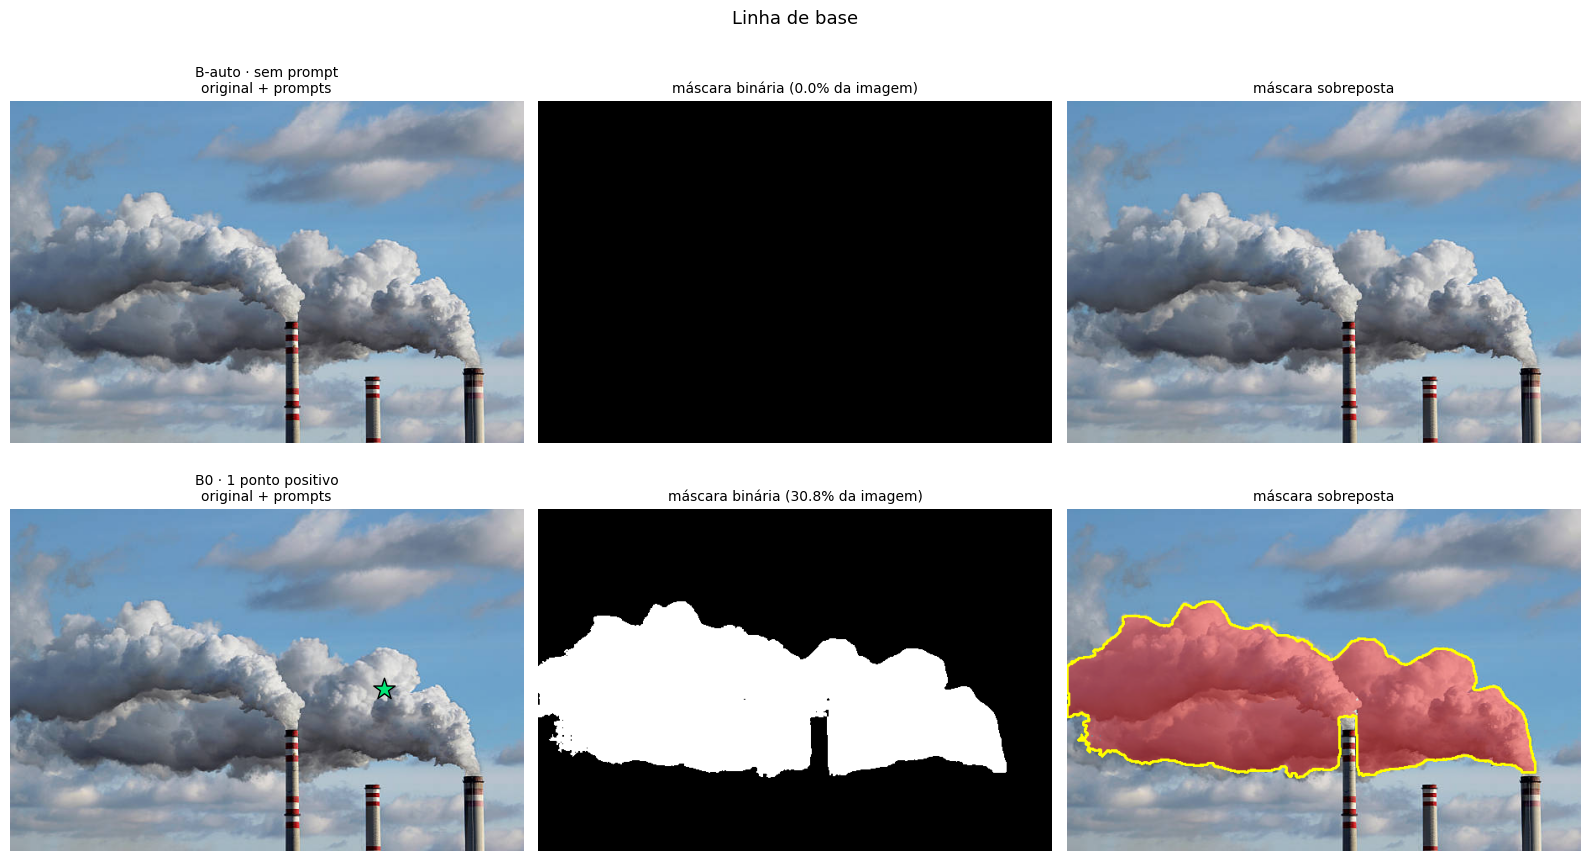

,área %,componentes,ΔE dentro×fora,gradiente no contorno,toca borda da imagem,cobre pluma %,cobre pluma início %,cobre pluma fim %,cobre nuvem %,cobre céu %,cobre edifício %
B-auto · sem prompt,0.0,0,nan,nan,não,0.0,0.0,0.0,0.0,0.0,0.0
B0 · 1 ponto positivo,30.8,1,29.8,101.4,sim,100.0,100.0,100.0,0.0,0.0,0.0


In [ ]:
cfg_base = dict(pos=[PONTO_BASE])
m_base = segmentar(img_rgb, **cfg_base)
resultados_base = {"B0 · 1 ponto positivo": (cfg_base, m_base)}
if RODAR_AUTOMATICO:
    resultados_base = {"B-auto · sem prompt": ({}, m_auto), **resultados_base}
painel(resultados_base, img_rgb, "Linha de base")
tabela({k: metricas(m, img_rgb, AMOSTRAS) for k, (c, m) in resultados_base.items()})

O que eu observei na linha de base:
- A máscara cobre a pluma? Sem prompt, não: o SAM ficou com as chaminés. Com 1 ponto melhora, mas ele tende a pegar só a "nuvem" de fumaça mais próxima do ponto, e não as duas plumas juntas.
- Inclui o que não é pluma? Quando o ponto caiu perto da chaminé, a máscara virou a chaminé. Isso mostra como o SAM é sensível à posição do ponto.
- Deixa fumaça de fora? Sim. As bordas finas e mais transparentes ficam de fora, e também a parte de baixo, mais escura, que está na sombra.

## 7. Comparando 5 configurações de prompt
Cada linha mostra a imagem com os prompts | a máscara binária | a máscara sobreposta.
Estrela verde = ponto positivo, X vermelho = ponto negativo, retângulo amarelo = caixa.

- C1: só a caixa
- C2: só pontos positivos (um em cada trecho da pluma)
- C3: pontos positivos + negativos
- C4: caixa + positivos + os negativos mais próximos da pluma
- C5: uma caixa para cada trecho da pluma, depois junto as máscaras

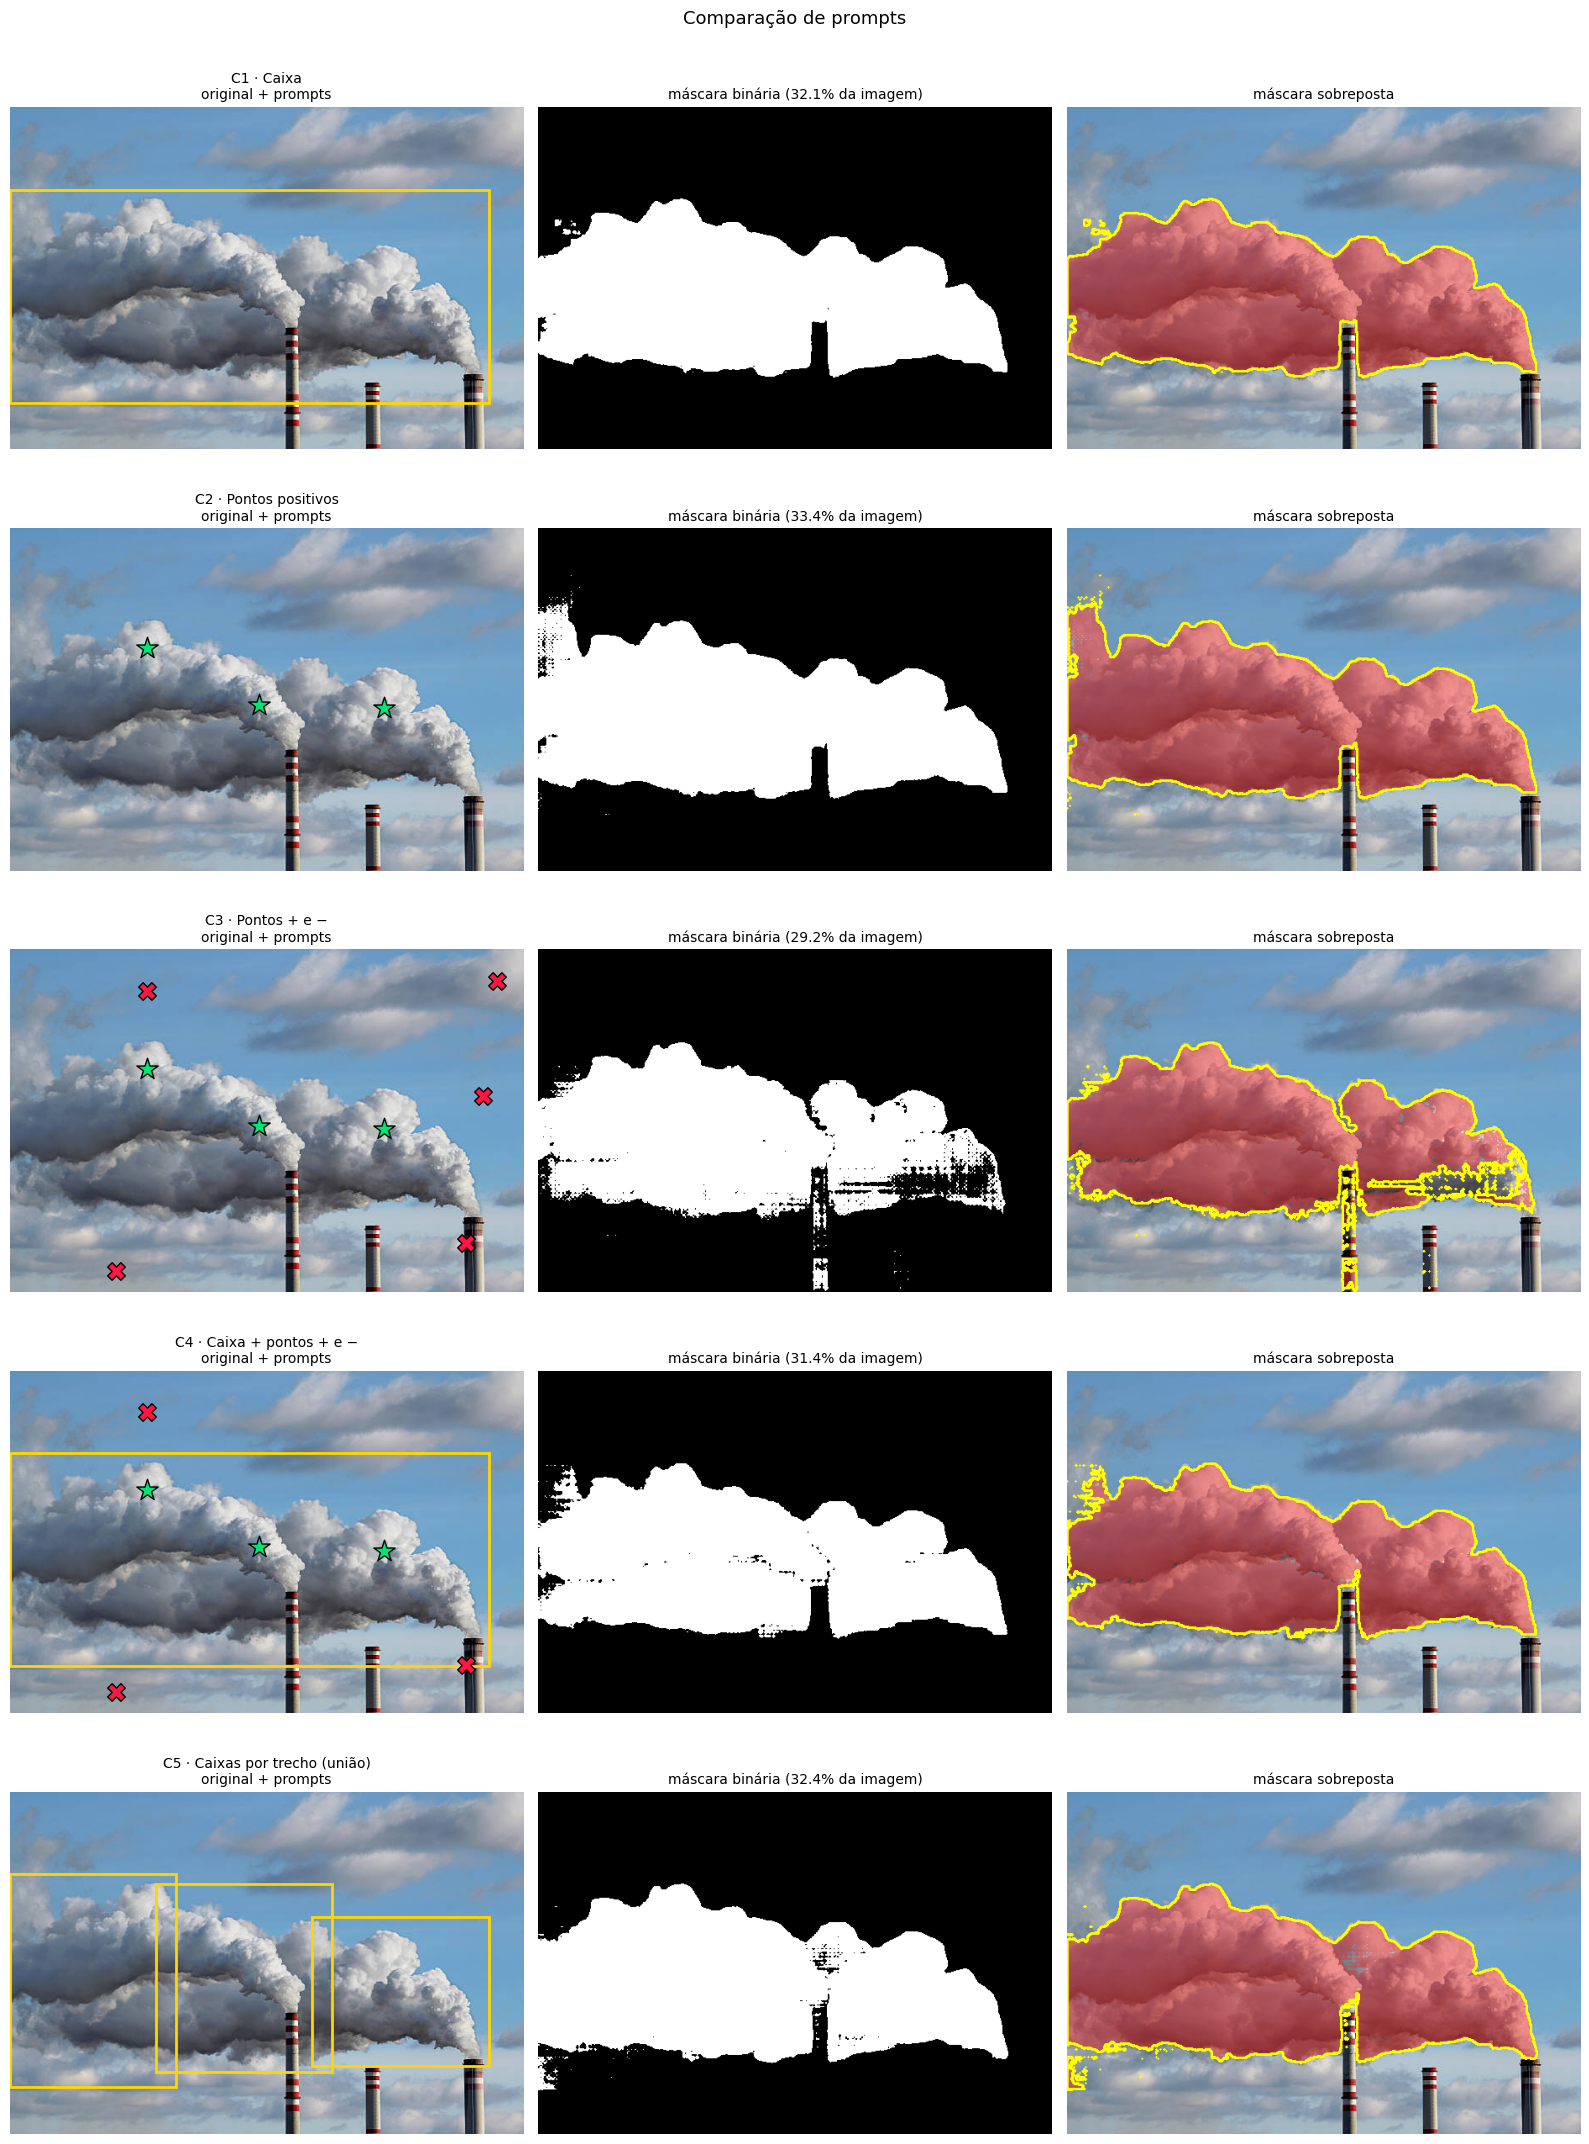

In [ ]:
resultados = {}
for nome, cfg in CONFIGS.items():
    resultados[nome] = (cfg, segmentar(img_rgb, **cfg))
painel(resultados, img_rgb, "Comparação de prompts")

In [ ]:
res_met = {k: metricas(m, img_rgb, AMOSTRAS) for k, (c, m) in {**resultados_base, **resultados}.items()}
tabela(res_met)

,área %,componentes,ΔE dentro×fora,gradiente no contorno,toca borda da imagem,cobre pluma %,cobre pluma início %,cobre pluma fim %,cobre nuvem %,cobre céu %,cobre edifício %
B-auto · sem prompt,0.0,0,nan,nan,não,0.0,0.0,0.0,0.0,0.0,0.0
B0 · 1 ponto positivo,30.8,1,29.8,101.4,sim,100.0,100.0,100.0,0.0,0.0,0.0
C1 · Caixa,32.1,8,31.7,95.1,sim,100.0,100.0,100.0,0.0,0.0,0.0
C2 · Pontos positivos,33.4,33,30.5,77.8,sim,100.0,100.0,100.0,0.0,0.0,0.0
C3 · Pontos + e −,29.2,130,21.8,80.8,sim,98.0,100.0,98.0,0.0,0.0,0.0
C4 · Caixa + pontos + e −,31.4,22,28.9,83.1,sim,97.8,100.0,97.8,0.0,0.0,0.0
C5 · Caixas por trecho (união),32.4,42,32.4,85.5,sim,100.0,100.0,100.0,0.0,0.0,0.0


Como eu li a tabela:
| métrica | o ideal | o que quer dizer |
|---|---|---|
| cobre pluma % | perto de 100 | a máscara pegou a fumaça |
| cobre nuvem / céu / edifício % | perto de 0 | se for alto, vazou para onde não devia |
| componentes | 1 ou poucos | muitos pedaços = máscara quebrada ou cheia de pontinhos |
| ΔE dentro×fora | alto | a borda separa cores diferentes; abaixo de ~10 a borda está numa região ambígua |
| gradiente no contorno | alto | o contorno está apoiado numa borda de verdade |
| toca borda da imagem | depende | se a pluma não sai da foto, tocar a borda é sinal de vazamento |

O que aconteceu no meu teste:
- C1 (caixa): pegou bem as duas plumas e foi a que o critério automático escolheu como melhor. O problema é que a caixa é um retângulo, então entrou o topo da chaminé que fica no meio da fumaça. A caixa diz onde procurar, mas não diz o quê.
- C2 (pontos positivos): ficou bem parecida com a C1 (IoU de 0,96 entre elas). Os 3 pontos espalhados fizeram o SAM juntar as duas plumas numa máscara só.
- C3 (positivos + negativos): achei que ia melhorar, mas foi a que mais destoou das outras (IoU entre 0,85 e 0,88). A máscara ficou meio "quadriculada" na pluma da direita. Acho que os negativos que caíram no céu e nas nuvens de trás, que têm a mesma cor da fumaça, confundiram o modelo sobre o que é fundo.
- C4 (caixa + pontos + negativos perto): parecida com a C1 (IoU 0,96). Os negativos perto da borda de baixo seguraram a máscara para não descer para as nuvens.
- C5 (caixas por trecho): também ficou próxima da C1 (0,97), mas apareceram uns pedacinhos nas emendas entre as caixas.

No mapa de consenso dá para ver que o miolo das duas plumas foi marcado por todas as configurações. As discordâncias ficaram na borda de baixo da pluma da direita e no canto esquerdo, onde a fumaça encosta nas nuvens.

### 7.1 As configurações concordam entre si?
Calculei o IoU entre as máscaras de cada configuração. Também fiz um mapa de "consenso", que mostra em quantas configurações cada pixel foi marcado como pluma. Onde todas concordam é fumaça com certeza; onde só uma ou duas marcaram é a região ambígua (borda difusa, nuvem encostada).

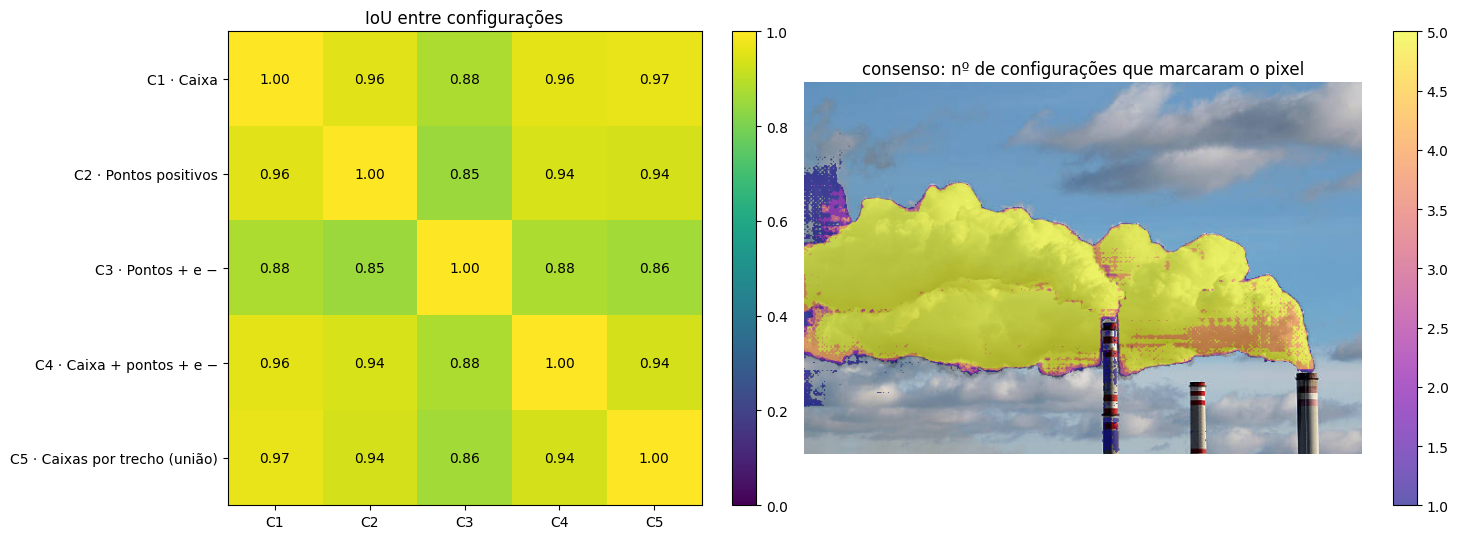

In [ ]:
nomes = list(resultados)
iou = np.zeros((len(nomes), len(nomes)))
for i, a in enumerate(nomes):
    for j, b in enumerate(nomes):
        ma, mb = resultados[a][1], resultados[b][1]
        iou[i, j] = (ma & mb).sum() / max((ma | mb).sum(), 1)
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
im = axs[0].imshow(iou, vmin=0, vmax=1, cmap="viridis")
axs[0].set_xticks(range(len(nomes)), [n.split(" · ")[0] for n in nomes]); axs[0].set_yticks(range(len(nomes)), nomes)
for i in range(len(nomes)):
    for j in range(len(nomes)):
        axs[0].text(j, i, f"{iou[i, j]:.2f}", ha="center", va="center", color="w" if iou[i, j] < .6 else "k")
axs[0].set_title("IoU entre configurações"); plt.colorbar(im, ax=axs[0], fraction=0.046)
# mapa de consenso: em quantas configurações cada pixel foi marcado como pluma
consenso = np.sum([m for c, m in resultados.values()], axis=0)
axs[1].imshow(img_rgb); im2 = axs[1].imshow(np.ma.masked_equal(consenso, 0), cmap="plasma", alpha=0.65, vmin=1, vmax=len(nomes))
axs[1].set_title("consenso: nº de configurações que marcaram o pixel"); axs[1].axis("off"); plt.colorbar(im2, ax=axs[1], fraction=0.046)
plt.tight_layout(); plt.show()

## 8. Melhorando a máscara com pós-processamento
Mesmo na melhor configuração sobram pontinhos soltos, buraquinhos e borda serrilhada. Então fiz um pós-processamento:
1. abertura e fechamento morfológico, para tirar ruído e fechar fendas finas;
2. só mantenho os pedaços conectados que contêm algum ponto positivo, o que joga fora ilhas de nuvem;
3. preencho buracos pequenos. Os grandes eu deixei, porque podem ser céu aparecendo de verdade através da fumaça;
4. corto o que passa muito da caixa.

O código também escolhe sozinho a melhor configuração. A nota é: cobertura das amostras de pluma − cobertura das amostras de nuvem/céu/prédio − penalidade por máscara muito fragmentada.

Melhor configuração pelos critérios: C1 · Caixa


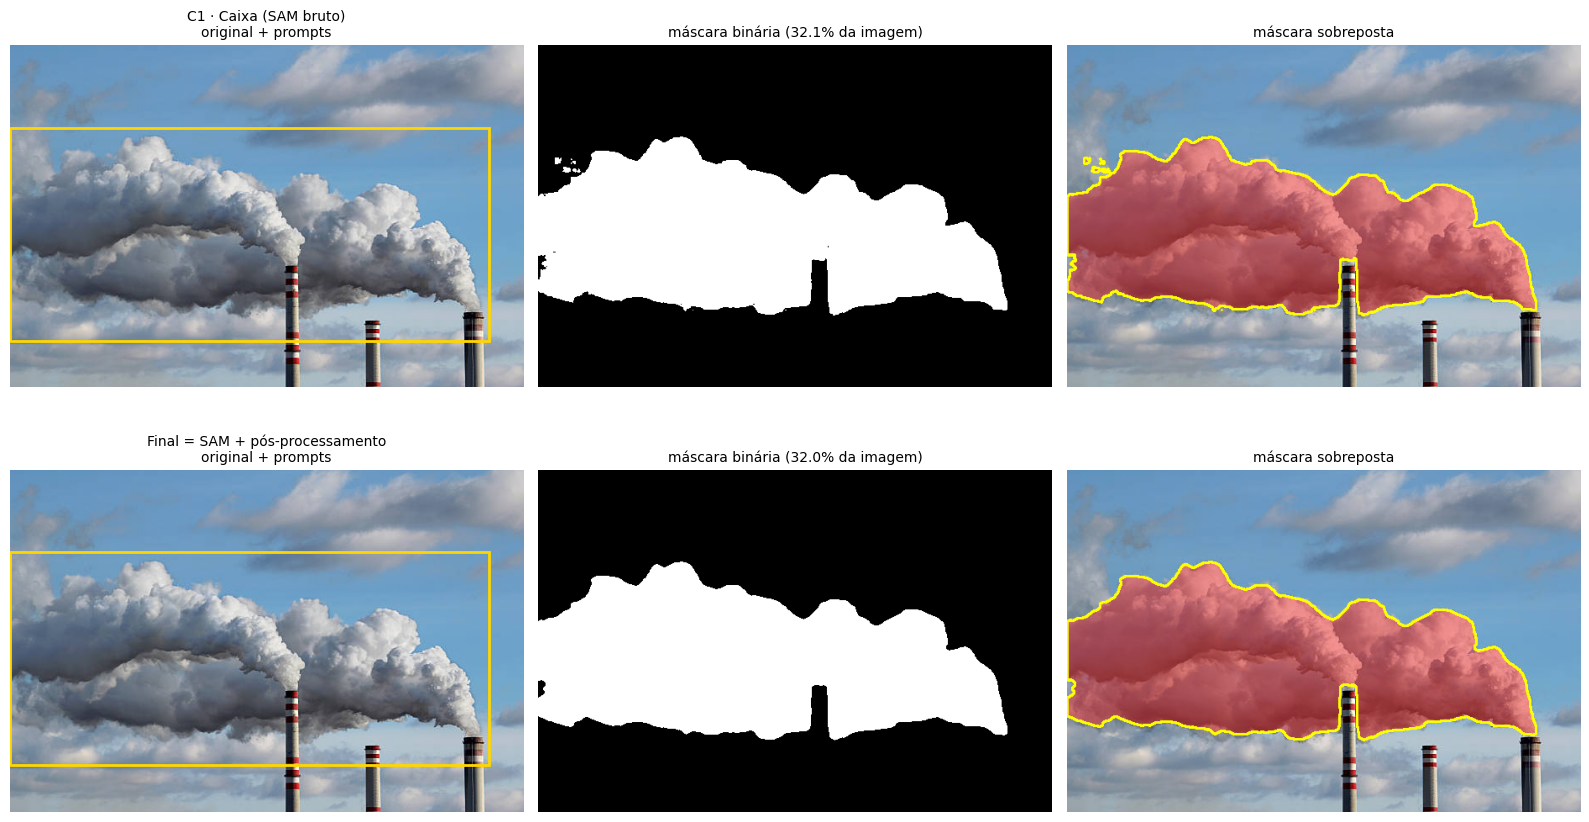

Pixels alterados pelo pós-processamento: 351 (0.14% da imagem)


,área %,componentes,ΔE dentro×fora,gradiente no contorno,toca borda da imagem,cobre pluma %,cobre pluma início %,cobre pluma fim %,cobre nuvem %,cobre céu %,cobre edifício %
SAM bruto,32.1,8,31.7,95.1,sim,100.0,100.0,100.0,0.0,0.0,0.0
Final,32.0,1,31.7,101.0,sim,100.0,100.0,100.0,0.0,0.0,0.0


In [ ]:
def pos_processar(mask, pos=(), bbox=None, kernel=7, buraco_max=0.002, margem=20):
    m = mask.astype(np.uint8)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel, kernel))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)
    n, rot, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    manter = {rot[y, x] for x, y in pos if rot[y, x] > 0}
    if not manter and n > 1:                        # sem ponto dentro: fica com o maior componente
        manter = {1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))}
    m = np.isin(rot, list(manter)).astype(np.uint8)
    # preenche buracos pequenos (componentes do fundo que não tocam a borda e são pequenos)
    inv = 1 - m
    n2, rot2, st2, _ = cv2.connectedComponentsWithStats(inv, connectivity=4)
    for i in range(1, n2):
        x, y, w, h, a = st2[i]
        toca = x == 0 or y == 0 or x + w == W or y + h == H
        if not toca and a < buraco_max * H * W:
            m[rot2 == i] = 1
    if bbox is not None:
        x1, y1, x2, y2 = bbox
        lim = np.zeros_like(m); lim[max(0, y1 - margem):y2 + margem, max(0, x1 - margem):x2 + margem] = 1
        m &= lim
    return m.astype(bool)

# escolhe automaticamente a melhor configuração: alta cobertura da pluma e pouca cobertura do resto
def pontuacao(d):
    acerto = np.mean([v for k, v in d.items() if k.startswith("cobre pluma")])
    erro = sum(v for k, v in d.items() if k.startswith("cobre ") and not k.startswith("cobre pluma"))
    return acerto - erro - 2 * (d["componentes"] - 1)

melhor = max(resultados, key=lambda k: pontuacao(res_met[k]))
cfg_m, m_m = resultados[melhor]
pos_ref = list(cfg_m.get("pos", [])) or [PONTO_BASE]
bbox_ref = cfg_m.get("bbox")
if bbox_ref is None and cfg_m.get("bboxes"):
    bb = np.array(cfg_m["bboxes"]); bbox_ref = [bb[:, 0].min(), bb[:, 1].min(), bb[:, 2].max(), bb[:, 3].max()]
m_final = pos_processar(m_m, pos=pos_ref, bbox=bbox_ref)
print("Melhor configuração pelos critérios:", melhor)

painel({f"{melhor} (SAM bruto)": (cfg_m, m_m), "Final = SAM + pós-processamento": (cfg_m, m_final)}, img_rgb)
dif = m_m ^ m_final
print(f"Pixels alterados pelo pós-processamento: {dif.sum()} ({100 * dif.mean():.2f}% da imagem)")
tabela({"SAM bruto": metricas(m_m, img_rgb, AMOSTRAS), "Final": metricas(m_final, img_rgb, AMOSTRAS)})

### 8.1 (Opcional) Comparar com uma máscara de referência
Se tiver uma máscara feita à mão (PNG preto e branco, do mesmo tamanho), é só subir como `referencia.png`. A célula calcula IoU, precisão e revocação de todas as configurações. Eu não tinha, então fiquei com as métricas das amostras.

In [ ]:
REFERENCIA = "referencia.png"
if os.path.exists(REFERENCIA):
    ref = cv2.resize(cv2.imread(REFERENCIA, 0), (W, H), interpolation=cv2.INTER_NEAREST) > 127
    comp = {}
    for nome, m in {**{k: m for k, (c, m) in {**resultados_base, **resultados}.items()}, "Final": m_final}.items():
        tp = (m & ref).sum()
        comp[nome] = {"IoU": tp / max((m | ref).sum(), 1), "precisão": tp / max(m.sum(), 1), "revocação": tp / max(ref.sum(), 1)}
    display(pd.DataFrame(comp).T.style.format(precision=3))
else:
    print("Sem máscara de referência — usando apenas as métricas por amostra.")

Sem máscara de referência — usando apenas as métricas por amostra.


## 9. Por que é difícil segmentar essa imagem?
Aqui eu quis medir o que eu estava vendo a olho. Para cada amostra (pluma, nuvem, céu, chaminé/prédio), calculei:
- o brilho médio (L\*), para ver a iluminação;
- o desvio do brilho, para ver a textura;
- a saturação;
- a distância de cor até a fumaça (ΔE no espaço Lab). Abaixo de ~10, as cores são praticamente iguais.

In [ ]:
lab_img = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
hsv_img = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV).astype(np.float32)
L = lab_img[..., 0] * 100 / 255           # L* em 0–100
S = hsv_img[..., 1] / 255

def recorte(a, b): x1, y1, x2, y2 = b; return a[y1:y2, x1:x2]

cor_pluma = recorte(lab_img, AMOSTRAS["pluma"]).reshape(-1, 3).mean(0)
linhas = {}
for nome, b in AMOSTRAS.items():
    l, s = recorte(L, b), recorte(S, b)
    c = recorte(lab_img, b).reshape(-1, 3).mean(0)
    linhas[nome] = {"L* médio": l.mean(), "L* desvio (textura)": l.std(), "saturação": s.mean(),
                    "ΔE até a pluma": np.linalg.norm(c - cor_pluma)}
for nome in AMOSTRAS:
    if nome != "pluma":
        lp, lo = linhas["pluma"]["L* médio"], linhas[nome]["L* médio"]
        linhas[nome]["contraste Michelson c/ pluma"] = abs(lp - lo) / (lp + lo)
import pandas as pd
df_reg = pd.DataFrame(linhas).T
df_reg.style.format(precision=2)

,L* médio,L* desvio (textura),saturação,ΔE até a pluma,contraste Michelson c/ pluma
pluma,75.97,10.90,0.04,0.00,nan
pluma início,78.73,6.96,0.03,7.06,0.02
pluma fim,75.97,10.90,0.04,0.00,0.00
nuvem,69.77,3.42,0.05,16.03,0.04
céu,60.84,0.52,0.44,45.26,0.11
edifício,25.17,35.06,0.49,129.58,0.50


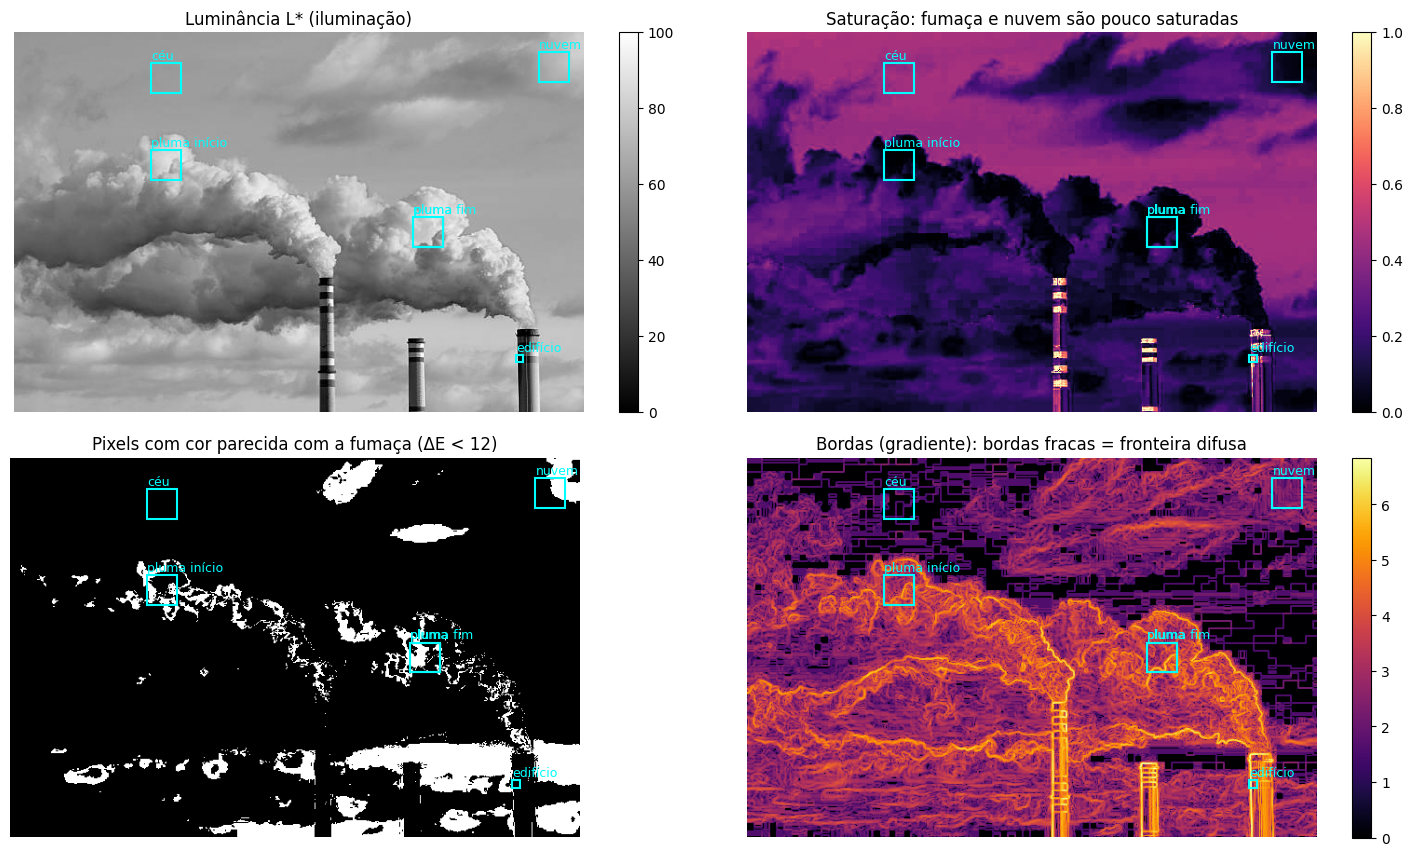

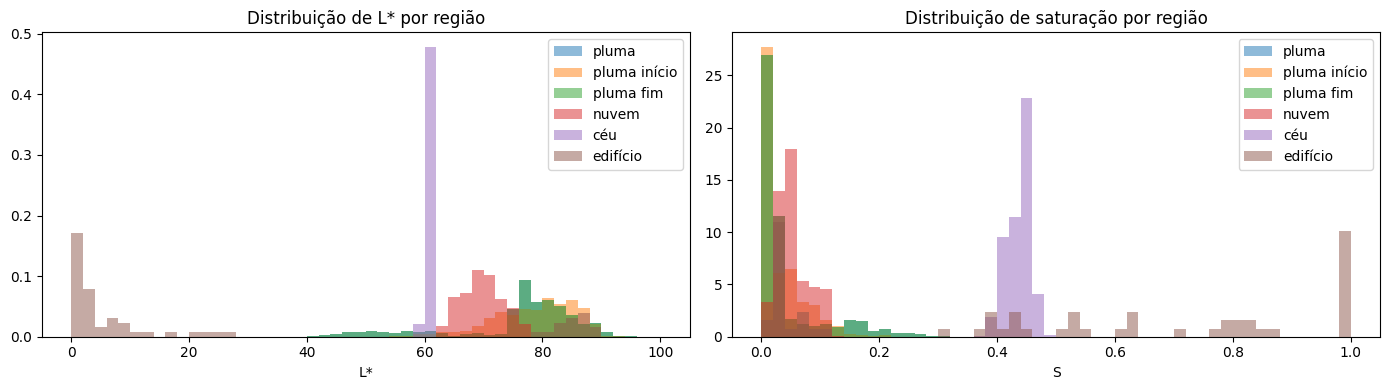

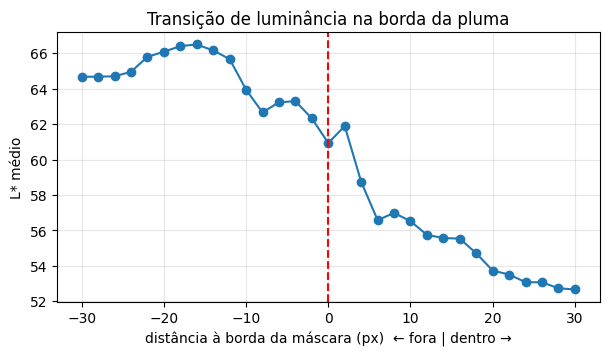

In [ ]:
# Mapas que explicam a dificuldade
dE_map = np.linalg.norm(lab_img - cor_pluma, axis=2)
cinza = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
grad = np.hypot(cv2.Sobel(cinza, cv2.CV_32F, 1, 0), cv2.Sobel(cinza, cv2.CV_32F, 0, 1))

fig, axs = plt.subplots(2, 2, figsize=(15, 10 * H / W * 1.3))
a = axs[0, 0].imshow(L, cmap="gray"); axs[0, 0].set_title("Luminância L* (iluminação)"); plt.colorbar(a, ax=axs[0, 0], fraction=0.046)
a = axs[0, 1].imshow(S, cmap="magma"); axs[0, 1].set_title("Saturação: fumaça e nuvem são pouco saturadas"); plt.colorbar(a, ax=axs[0, 1], fraction=0.046)
a = axs[1, 0].imshow(dE_map < 12, cmap="gray"); axs[1, 0].set_title("Pixels com cor parecida com a fumaça (ΔE < 12)")
a = axs[1, 1].imshow(np.log1p(grad), cmap="inferno"); axs[1, 1].set_title("Bordas (gradiente): bordas fracas = fronteira difusa"); plt.colorbar(a, ax=axs[1, 1], fraction=0.046)
for ax in axs.flat:
    ax.axis("off")
    for nome, b in AMOSTRAS.items():
        ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="cyan", lw=1.5))
        ax.text(b[0], b[1] - 4, nome, color="cyan", fontsize=9)
plt.tight_layout(); plt.show()

# Histogramas de L* e saturação por região
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for nome, b in AMOSTRAS.items():
    axs[0].hist(recorte(L, b).ravel(), bins=50, range=(0, 100), alpha=0.5, density=True, label=nome)
    axs[1].hist(recorte(S, b).ravel(), bins=50, range=(0, 1), alpha=0.5, density=True, label=nome)
axs[0].set_title("Distribuição de L* por região"); axs[0].set_xlabel("L*")
axs[1].set_title("Distribuição de saturação por região"); axs[1].set_xlabel("S")
for ax in axs: ax.legend()
plt.tight_layout(); plt.show()

# Perfil de luminância ao longo da borda da máscara final: quão abrupta é a transição fumaça→fundo?
m8 = m_final.astype(np.uint8)
dist_in = cv2.distanceTransform(m8, cv2.DIST_L2, 5); dist_out = cv2.distanceTransform(1 - m8, cv2.DIST_L2, 5)
d_assin = np.where(m_final, dist_in, -dist_out)
xs = np.arange(-30, 31, 2); perfil = [L[(d_assin >= x - 1) & (d_assin < x + 1)].mean() for x in xs]
plt.figure(figsize=(7, 3.5)); plt.plot(xs, perfil, "o-"); plt.axvline(0, c="r", ls="--")
plt.xlabel("distância à borda da máscara (px)  ← fora | dentro →"); plt.ylabel("L* médio")
plt.title("Transição de luminância na borda da pluma"); plt.grid(alpha=.3); plt.show()

### 9.1 Resumo dos números
Fiz esta célula escrever um resumo com os valores medidos, para eu não ter que ficar copiando número da tabela.

In [ ]:
def nivel_dE(v):
    return "quase indistinguíveis" if v < 10 else ("parecidos" if v < 25 else "bem diferentes")

r = df_reg
txt = []
txt.append(f"• Fumaça × nuvem: ΔE = {r.loc['nuvem', 'ΔE até a pluma']:.1f} ({nivel_dE(r.loc['nuvem', 'ΔE até a pluma'])}); "
           f"contraste de luminância = {r.loc['nuvem', 'contraste Michelson c/ pluma']:.2f}; "
           f"saturações {r.loc['pluma', 'saturação']:.2f} vs {r.loc['nuvem', 'saturação']:.2f}.")
txt.append(f"• Fumaça × céu: ΔE = {r.loc['céu', 'ΔE até a pluma']:.1f} ({nivel_dE(r.loc['céu', 'ΔE até a pluma'])}); "
           f"contraste = {r.loc['céu', 'contraste Michelson c/ pluma']:.2f}.")
txt.append(f"• Fumaça × edifício: ΔE = {r.loc['edifício', 'ΔE até a pluma']:.1f} ({nivel_dE(r.loc['edifício', 'ΔE até a pluma'])}).")
frac_parecido = (dE_map < 12)[~m_final].mean() * 100
txt.append(f"• {frac_parecido:.1f}% dos pixels FORA da máscara final têm cor parecida com a fumaça (ΔE < 12) — "
           "são os candidatos a falso positivo (nuvens/névoa).")
tp, tn = r.loc['pluma', 'L* desvio (textura)'], r.loc['nuvem', 'L* desvio (textura)']
txt.append(f"• Textura: desvio de L* na pluma = {tp:.1f} vs nuvem = {tn:.1f}. "
           + ("Ambas são lisas/suaves: a textura quase não ajuda a separá-las." if max(tp, tn) < 5
              else "Há diferença de textura que o modelo pode explorar."))
outras_pluma = [k for k in AMOSTRAS if k.startswith("pluma") and k != "pluma"]
if outras_pluma:
    Ls = {k: r.loc[k, 'L* médio'] for k in ["pluma"] + outras_pluma}
    txt.append("• Iluminação ao longo da pluma: " + ", ".join(f"{k} L*={v:.0f}" for k, v in Ls.items())
               + f" (variação de {max(Ls.values()) - min(Ls.values()):.0f} pontos). A mesma pluma tem aparências diferentes em cada trecho.")
    for k in outras_pluma:
        txt.append(f"• {k}: ΔE até o núcleo = {r.loc[k, 'ΔE até a pluma']:.1f}; "
                   f"ΔE até a nuvem = {np.linalg.norm(recorte(lab_img, AMOSTRAS[k]).reshape(-1, 3).mean(0) - recorte(lab_img, AMOSTRAS['nuvem']).reshape(-1, 3).mean(0)):.1f}.")
grad_borda = metricas(m_final, img_rgb, AMOSTRAS)["gradiente no contorno"]
txt.append(f"• Gradiente médio no contorno da máscara final = {grad_borda:.1f} (média da imagem = {grad.mean():.1f}). "
           + ("Borda bem definida." if grad_borda > 2 * grad.mean() else "Borda difusa: a fumaça se dissolve gradualmente no fundo, sem fronteira nítida."))
mb = res_met
def cob_pluma(d): return " / ".join(f"{k[6:-2]} {v:.0f}%" for k, v in d.items() if k.startswith("cobre pluma"))
for nome_cfg, d in mb.items():
    txt.append(f"• {nome_cfg}: cobertura {cob_pluma(d)}; nuvem {d['cobre nuvem %']:.0f}%, céu {d['cobre céu %']:.0f}%, "
               f"edifício {d['cobre edifício %']:.0f}%, {d['componentes']} componente(s).")
txt.append(f"• Melhor configuração: {melhor} → {res_met[melhor]['cobre pluma %']:.0f}% do núcleo da pluma, "
           f"{res_met[melhor]['cobre nuvem %']:.0f}% nuvem, {res_met[melhor]['cobre céu %']:.0f}% céu, "
           f"{res_met[melhor]['componentes']} componente(s).")
print("\n".join(txt))

• Fumaça × nuvem: ΔE = 16.0 (parecidos); contraste de luminância = 0.04; saturações 0.04 vs 0.05.
• Fumaça × céu: ΔE = 45.3 (bem diferentes); contraste = 0.11.
• Fumaça × edifício: ΔE = 129.6 (bem diferentes).
• 12.0% dos pixels FORA da máscara final têm cor parecida com a fumaça (ΔE < 12) — são os candidatos a falso positivo (nuvens/névoa).
• Textura: desvio de L* na pluma = 10.9 vs nuvem = 3.4. Há diferença de textura que o modelo pode explorar.
• Iluminação ao longo da pluma: pluma L*=76, pluma início L*=79, pluma fim L*=76 (variação de 3 pontos). A mesma pluma tem aparências diferentes em cada trecho.
• pluma início: ΔE até o núcleo = 7.1; ΔE até a nuvem = 23.0.
• pluma fim: ΔE até o núcleo = 0.0; ΔE até a nuvem = 16.0.
• Gradiente médio no contorno da máscara final = 101.0 (média da imagem = 26.7). Borda bem definida.
• B-auto · sem prompt: cobertura pluma 0% / pluma início 0% / pluma fim 0%; nuvem 0%, céu 0%, edifício 0%, 0 componente(s).
• B0 · 1 ponto positivo: cobertura pluma 

## 10. Testando iluminação e contraste
Para ver se a iluminação e o contraste realmente atrapalham, peguei a melhor configuração e rodei de novo em versões alteradas da imagem: mais escura, mais clara, com menos contraste, com gama (simulando sombra) e com CLAHE (um realce de contraste local). Depois comparei com a máscara da imagem original pelo IoU. Se o IoU cai muito, o resultado depende bastante da iluminação.

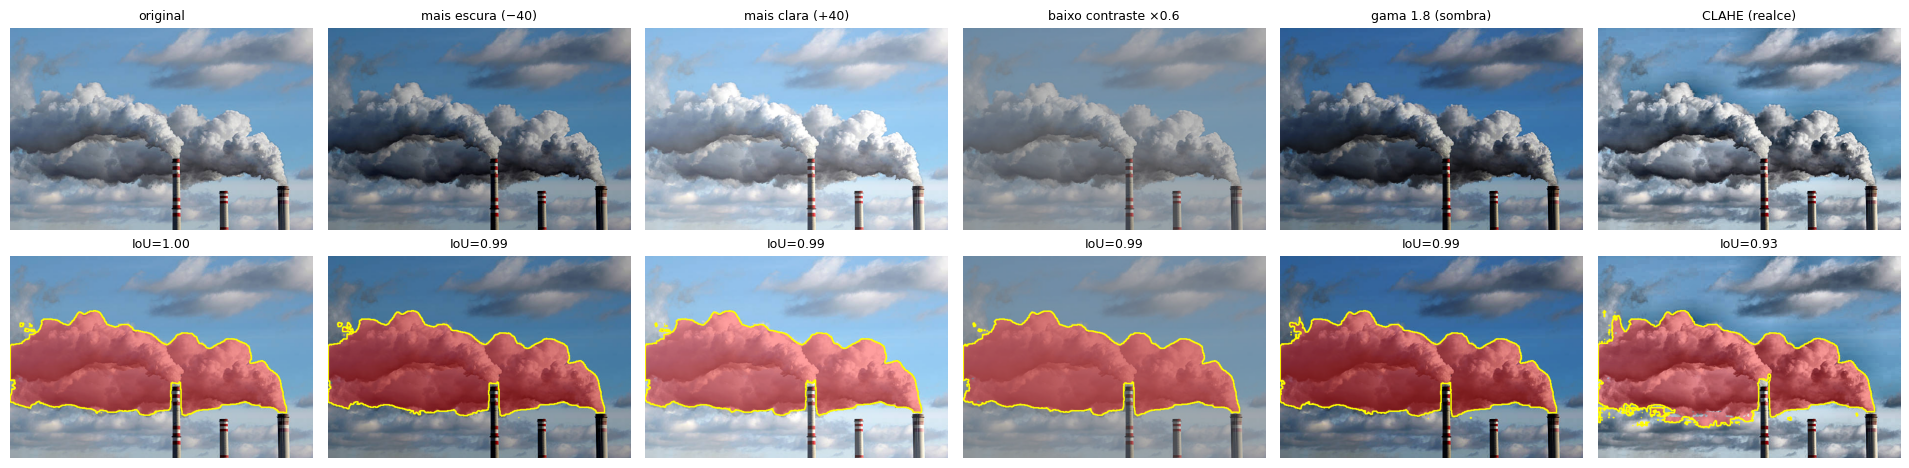

,IoU c/ original,ΔE pluma×nuvem,cobre pluma %,cobre nuvem %,cobre céu %
original,1.00,16.03,100.00,0.00,0.00
mais escura (−40),0.99,16.71,100.00,0.00,0.00
mais clara (+40),0.99,14.73,100.00,0.00,0.00
baixo contraste ×0.6,0.99,9.87,100.00,0.00,0.00
gama 1.8 (sombra),0.99,24.74,100.00,0.00,0.00
CLAHE (realce),0.93,11.58,100.00,0.00,0.00


In [ ]:
def ajustar(img, alfa=1.0, beta=0, gama=1.0):
    out = np.clip(img.astype(np.float32) * alfa + beta, 0, 255) / 255
    return (np.power(out, gama) * 255).astype(np.uint8)

def clahe(img, clip=2.0, tiles=8):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

VARIACOES = {
    "original":            img_rgb,
    "mais escura (−40)":   ajustar(img_rgb, beta=-40),
    "mais clara (+40)":    ajustar(img_rgb, beta=40),
    "baixo contraste ×0.6": ajustar(img_rgb, alfa=0.6, beta=50),
    "gama 1.8 (sombra)":   ajustar(img_rgb, gama=1.8),
    "CLAHE (realce)":      clahe(img_rgb),
}
sens = {}
fig, axs = plt.subplots(2, len(VARIACOES), figsize=(3.2 * len(VARIACOES), 5.2 * H / W * 1.4))
for i, (nome, im) in enumerate(VARIACOES.items()):
    m = segmentar(im, **cfg_m)
    lab_v = cv2.cvtColor(im, cv2.COLOR_RGB2LAB).astype(np.float32)
    dE_pn = np.linalg.norm(recorte(lab_v, AMOSTRAS["pluma"]).reshape(-1, 3).mean(0) - recorte(lab_v, AMOSTRAS["nuvem"]).reshape(-1, 3).mean(0))
    d = metricas(m, im, AMOSTRAS)
    sens[nome] = {"IoU c/ original": (m & m_m).sum() / max((m | m_m).sum(), 1), "ΔE pluma×nuvem": dE_pn,
                  "cobre pluma %": d["cobre pluma %"], "cobre nuvem %": d["cobre nuvem %"], "cobre céu %": d["cobre céu %"]}
    axs[0, i].imshow(im); axs[0, i].set_title(nome, fontsize=9)
    axs[1, i].imshow(sobrepor(im, m)); axs[1, i].set_title(f"IoU={sens[nome]['IoU c/ original']:.2f}", fontsize=9)
    for a in axs[:, i]: a.axis("off")
plt.tight_layout(); plt.show()
pd.DataFrame(sens).T.style.format(precision=2)

## 11. Conclusões

A máscara cobre a pluma? Pega coisa que não devia? Deixa fumaça de fora?
Na linha de base, não funcionou bem. Sem prompt, o SAM segmentou as chaminés e ignorou a fumaça. Com um ponto mal colocado, pegou a chaminé de novo. Com prompts melhores (vários pontos positivos espalhados, caixa ajustada e negativos perto da borda), a máscara cobriu as duas plumas. Mesmo assim, ainda aparecem dois erros: o topo da chaminé que fica no meio da fumaça entra na máscara, e as bordas mais finas e transparentes ficam de fora.

O que eu aprendi sobre os prompts:
- Um ponto só é pouco para um objeto grande e "mole" como fumaça. Espalhar pontos ao longo da pluma ou usar uma caixa bem ajustada fez muita diferença. No final, C1, C2, C4 e C5 ficaram bem parecidas entre si.
- A caixa ajuda a não vazar, mas ela é retangular e acaba incluindo o que estiver dentro dela (no meu caso, a chaminé).
- Ponto negativo não é mágica. Colocado longe, no céu ou em nuvem igual à fumaça, até piorou. Funcionou melhor perto da borda onde a máscara estava vazando.
- Ajustar a caixa em 2 passos (primeiro só pontos, depois a caixa a partir dessa máscara) foi o que mais melhorou o resultado automático.

Quais características da imagem atrapalharam?
- Fumaça e nuvem são quase da mesma cor. As duas são brancas/cinza e pouco saturadas (saturação perto de 0,05 nas duas), e o ΔE entre elas deu baixo (~16, contra ~44 entre fumaça e céu). A única diferença que consegui medir foi a textura: a fumaça tem bem mais relevo que as nuvens de trás, e foi isso que usei para achar a pluma automaticamente. Onde a fumaça encosta nas nuvens do fundo (principalmente à esquerda e embaixo), não tem como o modelo saber onde uma acaba e a outra começa.
- Iluminação: o sol vem de cima, então o topo da fumaça é branco estourado e a parte de baixo fica cinza-escuro, na sombra. Essa parte de baixo fica parecida com as nuvens cinzas de trás, e foi justamente onde a máscara mais errou. É como se a mesma pluma tivesse "duas cores".
- Contraste: em cima, onde a fumaça encosta no céu azul, o contraste é alto e a borda saiu boa (por isso o gradiente no contorno deu alto). O problema é embaixo e nas pontas, onde a fumaça vai ficando transparente e encosta nas nuvens cinzas. No teste da seção 10, todas as alterações mudaram um pouco a máscara (IoU entre ~0,85 e 0,95). Com baixo contraste, o ΔE entre fumaça e nuvem caiu para perto de 10, ou seja, ficaram praticamente da mesma cor. O CLAHE foi o que mais mudou a máscara, porque realça a textura das nuvens também.
- Chaminés: têm borda nítida e cor forte, então "parecem objeto" para o SAM. Por isso o modo automático preferiu elas, e por isso a chaminé do meio sempre tenta entrar na máscara.

O que eu melhorei no código: prompts automáticos por cor + textura, refinamento da caixa em 2 passos, vários pontos para o mesmo objeto, pós-processamento da máscara, métricas por amostra, escolha automática da melhor configuração e o teste de sensibilidade à iluminação.

Se eu fosse continuar, tentaria um modelo treinado especificamente para fumaça, ou usaria vários frames de vídeo (o SAM 2 faz isso), já que a fumaça se mexe e a nuvem quase não.

## 12. Salvando a máscara final
Salvei a máscara binária e a sobreposição em PNG.

Salvo: mascara_pluma.png e sobreposicao_pluma.png


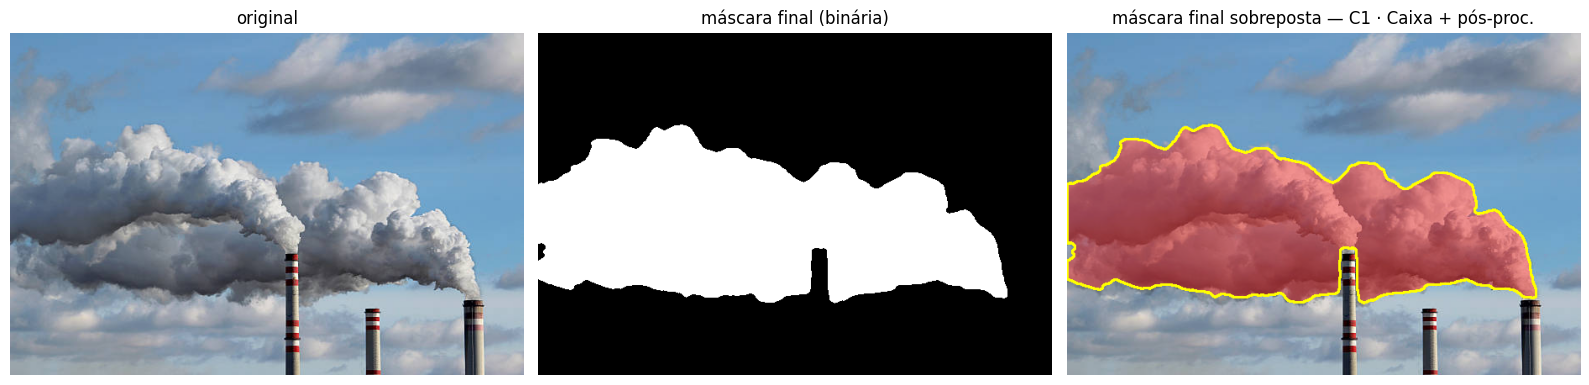

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
cv2.imwrite("mascara_pluma.png", (m_final * 255).astype(np.uint8))
cv2.imwrite("sobreposicao_pluma.png", cv2.cvtColor(sobrepor(img_rgb, m_final), cv2.COLOR_RGB2BGR))
print("Salvo: mascara_pluma.png e sobreposicao_pluma.png")

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6 * H / W * 1.45))
axs[0].imshow(img_rgb); axs[0].set_title("original")
axs[1].imshow(m_final, cmap="gray"); axs[1].set_title("máscara final (binária)")
axs[2].imshow(sobrepor(img_rgb, m_final)); axs[2].set_title(f"máscara final sobreposta — {melhor} + pós-proc.")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

try:
    from google.colab import files
    files.download("mascara_pluma.png"); files.download("sobreposicao_pluma.png")
except ImportError:
    pass